# Libraries



In [1]:
import sys
from pathlib import Path

# Add repo root so benchmarking.helpers is importable
_repo_root = Path.cwd().parents[3]
sys.path.insert(0, str(_repo_root))

# path to benchmarking/benchmarks
benchmarks_path = (_repo_root / "benchmarking" / "benchmarks").resolve()

from benchmarking.helpers.plot import (
    discover_benchmark_names,
    plot_overall_hitrate,
    plot_overall_ndcg,
    plot_overall_diversity,
    plot_overall_mrr,
    plot_group_bar_plot,
)

system_version = "ablation_v16_hybrid"
benchmark_names = discover_benchmark_names(benchmarks_path)

print("System version:", system_version)
print("Benchmarks discovered:", benchmark_names)


System version: ablation_v16_hybrid
Benchmarks discovered: ['Cloudbench', 'Commonobjectsbench', 'Firebench', 'INQUIRE', 'Sagebench']


# Evaluating ALL Benchmarks

Here we will evaluate the raw query metrics returned by all benchmarks for the **v16 query-time ablation** `ablation_v16_hybrid` (dense + BM25 hybrid (query_alpha=0.65, clip_alpha=0.7); CLIP rerank off).


## Overall Hit Rate Across Benchmarks

Hit rate (Success@25) = fraction of queries with at least one relevant image in the top 25.

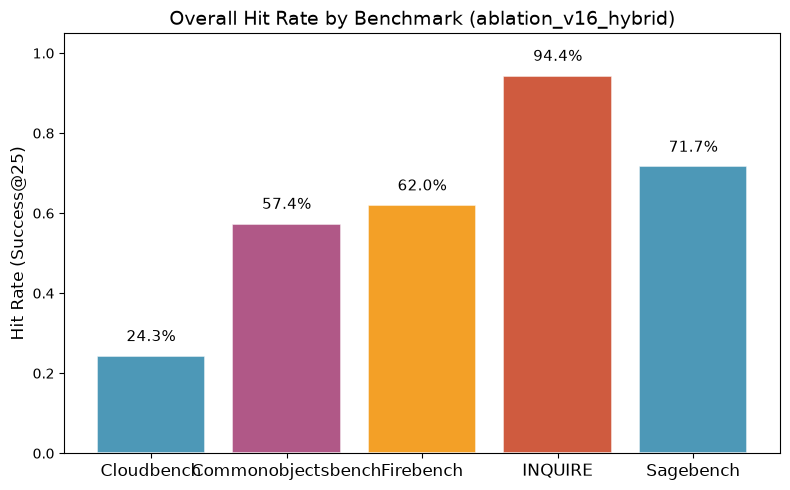

In [2]:
plot_overall_hitrate(
    system_version=system_version,
    base_path=benchmarks_path,
    response_limit=25
)

## Overall Diversity Across Benchmarks

Diversity measures the diversity of the retrieved images; higher means more diverse images are retrieved.

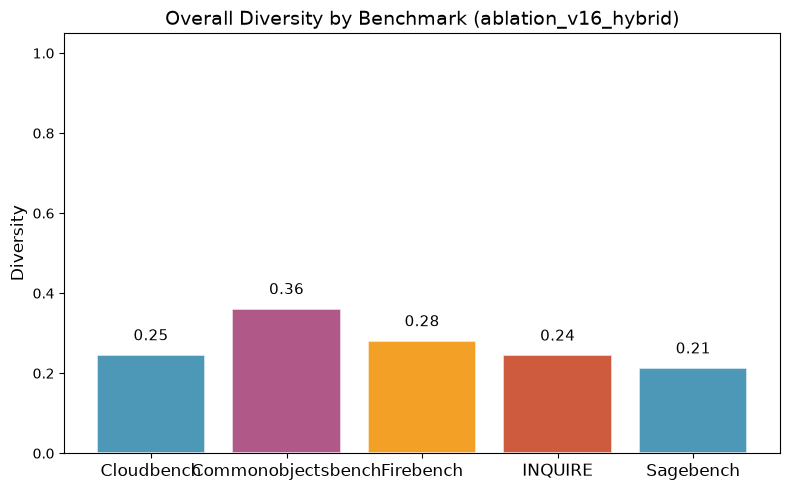

In [3]:
plot_overall_diversity(
    system_version=system_version,
    base_path=benchmarks_path,
)

## Overall MRR Across Benchmarks

MRR (Mean Reciprocal Rank) measures how early the first relevant result appears.


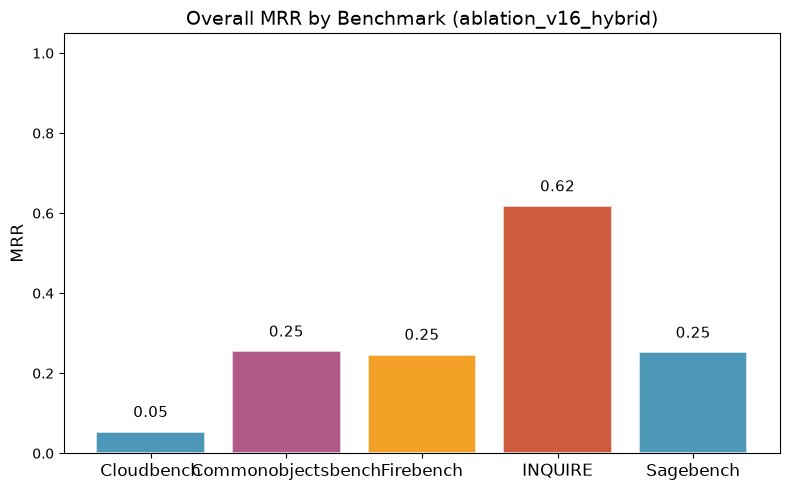

In [4]:
plot_overall_mrr(
    system_version=system_version,
    base_path=benchmarks_path,
)

## Overall NDCG Across Benchmarks

NDCG (Normalized Discounted Cumulative Gain) measures ranking quality; higher means relevant images are ranked higher.

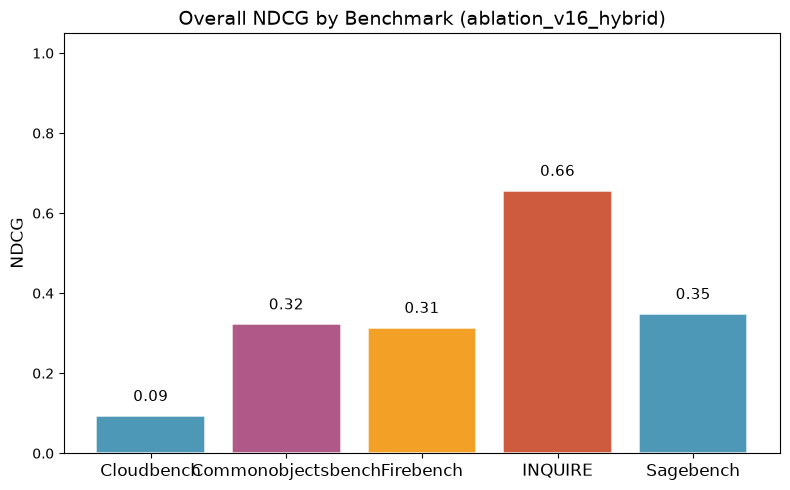

In [5]:
plot_overall_ndcg(
    system_version=system_version,
    base_path=benchmarks_path,
)

## Insights & Conclusion

`ablation_v16_hybrid` is a **v16 query-time architecture ablation**. Every bench is skip-index on the v15/v16 Milvus collections (no recaption). Flags: `EMBED_IMAGE=True, EMBED_CAPTION=True, ENABLE_BM25=True, ENABLE_RERANK=False`. Weights: `[0.455, 0.195, 0.35]`.

| Dataset | Queries | MRR | Success@K |
| ------- | ------- | --- | --------- |
| INQUIRE | 160 | 0.618 | 94.4% (@50) |
| Sagebench | 120 | 0.252 | 71.7% (@25) |
| Firebench | 100 | 0.247 | 62.0% (@25) |
| Cloudbench | 115 | 0.054 | 24.3% (@25) |
| Commonobjectsbench | 291 | 0.255 | 57.4% (@25) |

MRR uses `score_reciprocal_rank` when rerank is off and `rerank_score_reciprocal_rank` when rerank is on. Success@K is mean `hit` (independent of ranking column). Compare the five `overall/ablation_v16_*` notebooks and production `overall/v16`.
